[*] Mengunduh data historis ^GSPC (2012-01-01 s.d. 2026-11-14)...
[✓] Data historis siap: 3729 hari bursa (hingga 2026-11-13).
[*] Menjalankan simulasi proyeksi HMM (1077 hari bursa hingga 2030-12-31)...
[✓] Proyeksi hingga 2030-12-31 selesai. Total sampel keseluruhan: 4806 hari bursa.

RINGKASAN STATISTIK TIAP REGIME (2012 - 2030) -> UNTUK TABEL 4.1
Bearish (High Vol)   | Mean Return: -0.00204 | Volatilitas (Std):  0.03363 | Hari: 145
Sideways (Neutral)   | Mean Return:  0.00006 | Volatilitas (Std):  0.01263 | Hari: 1565
Bullish (Low Vol)    | Mean Return:  0.00094 | Volatilitas (Std):  0.00598 | Hari: 3096

MATRIKS TRANSISI PELUANG (URUTAN: Bearish, Sideways, Bullish)
                    Bearish (High Vol)  Sideways (Neutral)  Bullish (Low Vol)
Bearish (High Vol)               0.930               0.070              0.000
Sideways (Neutral)               0.007               0.954              0.039
Bullish (Low Vol)                0.000               0.019              0.981



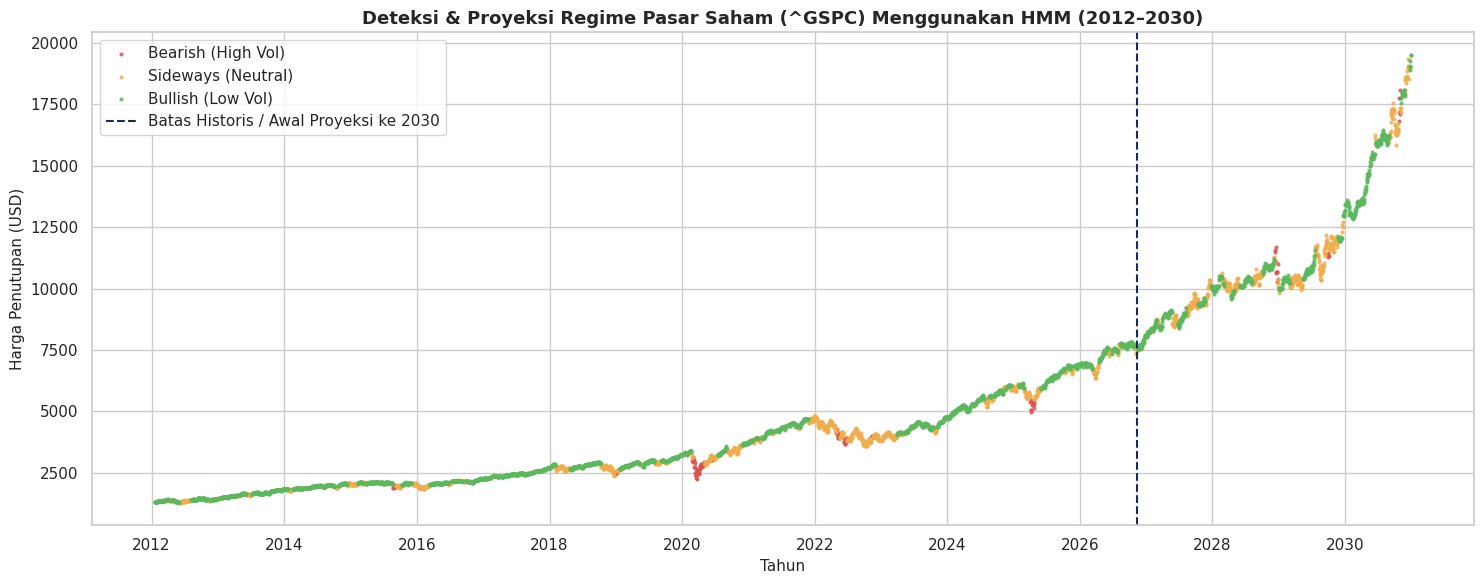

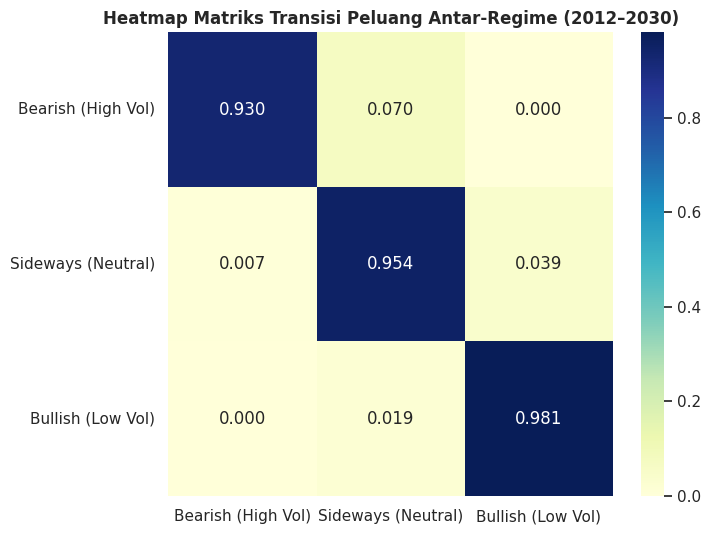

In [ ]:
!pip install -q hmmlearn yfinance

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from hmmlearn.hmm import GaussianHMM

warnings.filterwarnings("ignore")

class MarketRegimeForecaster:
    def __init__(self, ticker="^GSPC", n_regimes=3, vol_window=10, random_state=42):
        self.ticker = ticker
        self.n_regimes = n_regimes
        self.vol_window = vol_window
        self.random_state = random_state
        self.model = GaussianHMM(
            n_components=self.n_regimes,
            covariance_type="full",
            n_iter=200,
            random_state=self.random_state,
        )
        self.state_map = {}
        self.ordered_indices = []
        self.ordered_transmat = None

    def fetch_historical_data(self, start_date="2012-01-01", end_date="2026-11-14"):
        """Mengunduh data historis aktual (2012 - sekarang) dan menghitung fitur."""
        print(f"[*] Mengunduh data historis {self.ticker} ({start_date} s.d. {end_date})...")
        raw_df = yf.download(self.ticker, start=start_date, end=end_date, progress=False)

        if isinstance(raw_df.columns, pd.MultiIndex):
            raw_df.columns = raw_df.columns.get_level_values(0)

        df = raw_df[["Close"]].copy()
        df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))
        df["Volatility"] = df["Log_Return"].rolling(window=self.vol_window).std()
        df.dropna(inplace=True)
        df["Tipe_Data"] = "Historis (Aktual)"
        print(f"[✓] Data historis siap: {len(df)} hari bursa (hingga {df.index[-1].strftime('%Y-%m-%d')}).")
        return df

    def fit_and_decode(self, df):
        """Melatih Gaussian HMM (Baum-Welch) dan mengekstrak state (Viterbi)."""
        X = df[["Log_Return", "Volatility"]].values
        self.model.fit(X)
        df["State"] = self.model.predict(X)

        # Hitung statistik awal tiap state untuk pelabelan otomatis
        stats = []
        for s in range(self.n_regimes):
            sub = df[df["State"] == s]["Log_Return"]
            stats.append((s, sub.mean(), sub.std()))

        # Urutkan berdasarkan rata-rata return terendah ke tertinggi: Bearish -> Sideways -> Bullish
        stats.sort(key=lambda item: item[1])
        labels = ["Bearish (High Vol)", "Sideways (Neutral)", "Bullish (Low Vol)"]

        self.ordered_indices = [item[0] for item in stats]
        self.state_map = {stats[i][0]: labels[i] for i in range(self.n_regimes)}
        df["Regime"] = df["State"].map(self.state_map)

        # Susun ulang matriks transisi sesuai urutan [Bearish, Sideways, Bullish]
        self.ordered_transmat = self.model.transmat_[np.ix_(self.ordered_indices, self.ordered_indices)]
        return df

    def forecast_to_2030(self, df_hist, forecast_end="2030-12-31"):
        """Memproyeksikan pergerakan harga dan regime dari akhir data historis hingga 2030."""
        last_date = df_hist.index[-1]
        future_dates = pd.bdate_range(start=last_date + pd.Timedelta(days=1), end=forecast_end)

        if len(future_dates) == 0:
            return df_hist

        print(f"[*] Menjalankan simulasi proyeksi HMM ({len(future_dates)} hari bursa hingga {forecast_end})...")
        rng = np.random.RandomState(self.random_state)

        curr_state = int(df_hist["State"].iloc[-1])
        curr_price = float(df_hist["Close"].iloc[-1])

        sim_states, sim_prices, sim_returns = [], [], []
        transmat = self.model.transmat_
        means = self.model.means_
        covars = self.model.covars_

        for _ in range(len(future_dates)):
            # Transisi state berdasarkan rantai Markov
            next_state = rng.choice(self.n_regimes, p=transmat[curr_state])
            # Emisi return & volatilitas dari distribusi Gaussian state terpilih
            obs = rng.multivariate_normal(means[next_state], covars[next_state])
            daily_ret = np.clip(obs[0], -0.055, 0.055)  # Batas kewajaran harian

            next_price = curr_price * np.exp(daily_ret)
            sim_states.append(next_state)
            sim_prices.append(next_price)
            sim_returns.append(daily_ret)

            curr_state = next_state
            curr_price = next_price

        df_future = pd.DataFrame({
            "Close": sim_prices,
            "Log_Return": sim_returns,
            "State": sim_states,
            "Tipe_Data": "Proyeksi (2026–2030)"
        }, index=future_dates)

        df_future["Regime"] = df_future["State"].map(self.state_map)
        df_combined = pd.concat([df_hist, df_future])
        df_combined["Volatility"] = df_combined["Log_Return"].rolling(window=self.vol_window).std().bfill()

        print(f"[✓] Proyeksi hingga {forecast_end} selesai. Total sampel keseluruhan: {len(df_combined)} hari bursa.\n")
        return df_combined

    def print_report_summary(self, df_combined):
        """Mencetak angka statistik Tabel 4.1 dan Tabel 4.2 siap salin ke Word."""
        labels_ordered = ["Bearish (High Vol)", "Sideways (Neutral)", "Bullish (Low Vol)"]
        print("=" * 65)
        print("RINGKASAN STATISTIK TIAP REGIME (2012 - 2030) -> UNTUK TABEL 4.1")
        print("=" * 65)
        for lbl in labels_ordered:
            sub = df_combined[df_combined["Regime"] == lbl]
            print(f"{lbl:<20} | Mean Return: {sub['Log_Return'].mean():>8.5f} | "
                  f"Volatilitas (Std): {sub['Log_Return'].std():>8.5f} | Hari: {len(sub)}")

        print("\n" + "=" * 65)
        print("MATRIKS TRANSISI PELUANG (URUTAN: Bearish, Sideways, Bullish)")
        print("=" * 65)
        df_tm = pd.DataFrame(
            np.round(self.ordered_transmat, 3),
            index=labels_ordered,
            columns=labels_ordered
        )
        print(df_tm)
        print("=" * 65 + "\n")

    def plot_all(self, df_combined, split_date):
        """Menghasilkan dan menyimpan kedua grafik untuk Bab IV makalah."""
        sns.set_theme(style="whitegrid")
        palette = {
            "Bearish (High Vol)": "#d9534f",
            "Sideways (Neutral)": "#f0ad4e",
            "Bullish (Low Vol)": "#5cb85c"
        }

        # --- GRAFIK 1: DETEKSI & PROYEKSI REGIME (2012 - 2030) ---
        fig, ax = plt.subplots(figsize=(15, 6))
        for label, color in palette.items():
            sub = df_combined[df_combined["Regime"] == label]
            ax.scatter(sub.index, sub["Close"], label=label, c=color, s=4, alpha=0.75)

        # Garis batas pemisah antara data historis aktual dan zona proyeksi hingga 2030
        ax.axvline(pd.to_datetime(split_date), color="#142D5A", linestyle="--", linewidth=1.5,
                   label="Batas Historis / Awal Proyeksi ke 2030")

        ax.set_title(f"Deteksi & Proyeksi Regime Pasar Saham ({self.ticker}) Menggunakan HMM (2012–2030)",
                     fontsize=13, fontweight="bold")
        ax.set_xlabel("Tahun", fontsize=11)
        ax.set_ylabel("Harga Penutupan (USD)", fontsize=11)
        ax.legend(loc="upper left")
        plt.tight_layout()
        plt.savefig("grafik1_regime_2012_2030.png", dpi=300)
        plt.show()

        # --- GRAFIK 2: HEATMAP MATRIKS TRANSISI PELUANG ---
        labels_ordered = ["Bearish (High Vol)", "Sideways (Neutral)", "Bullish (Low Vol)"]
        plt.figure(figsize=(7.5, 5.5))
        sns.heatmap(
            self.ordered_transmat,
            annot=True,
            fmt=".3f",
            cmap="YlGnBu",
            xticklabels=labels_ordered,
            yticklabels=labels_ordered,
            cbar=True
        )
        plt.title("Heatmap Matriks Transisi Peluang Antar-Regime (2012–2030)", fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.savefig("grafik2_heatmap_2012_2030.png", dpi=300)
        plt.show()


# ==============================================================================
# JALANKAN PROGRAM UTAMA
# ==============================================================================
if __name__ == "__main__":
    forecaster = MarketRegimeForecaster(ticker="^GSPC", n_regimes=3, vol_window=10, random_state=42)

    # 1. Ambil data historis dari 2012 hingga hari ini (Nov 2026)
    df_historis = forecaster.fetch_historical_data(start_date="2012-01-01", end_date="2026-11-14")

    # 2. Latih model Gaussian HMM & lakukan decoding state
    df_historis = forecaster.fit_and_decode(df_historis)

    # 3. Proyeksikan lintasan pasar & regime hingga akhir 2030
    batas_historis = df_historis.index[-1]
    df_2012_2030 = forecaster.forecast_to_2030(df_historis, forecast_end="2030-12-31")

    # 4. Cetak hasil tabel statistik & matriks transisi ke konsol
    forecaster.print_report_summary(df_2012_2030)

    # 5. Tampilkan & simpan grafik (grafik1_regime_2012_2030.png & grafik2_heatmap_2012_2030.png)
    forecaster.plot_all(df_2012_2030, split_date=batas_historis)